# QORC — combined results & pitch figures

Pulls the results of **both** heads off disk and turns them into slide-ready
figures. Nothing is recomputed here except the family-level regrouping in
section 2; every number traces back to a `results.jsonl` produced by:

| head | notebook | run |
|---|---|---|
| supervised (closed-set attack classification) | `qorc_supervised_multiclass.ipynb` | `qorc_sup_runs/` |
| novelty (zero-day, normal-only training) | `qorc_zeroday_sweep_novelty.ipynb` | `qorc_nov_runs/` |

Every figure is saved to `pitch_figures/` as PNG (300 dpi, transparent-safe
white background) ready to drop into slides.

## Design language

* **Violet** (`#6D28E0`) — the quantum arm. The thing we are pitching, in the
  deck's house colour.
* **Dim grey** (`#B4B4B4`, thin, dashed, hollow markers) — the classical
  control. Present for honesty, deliberately quiet: a flat reference, not a
  competitor fighting for attention.
* Ordering is **low → high** on the x-axis so every chart reads as a rising
  story left to right.

## The headline metric is accuracy

Accuracy over the five classes (`normal` + the four attack families) leads the
deck. It moves honestly with capacity (95.6% → 97.9%) and the classical control
sits ~18 points below, so the gap is real and visible on a plain linear axis.

Because that range is narrow, section 2.1a re-plots it as **error rate on a
log10 axis** — the correct way to expand a high-accuracy band. See that section
for why `log10(accuracy)` itself would not work.

## 0. Setup

In [37]:
import json, math, glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# ------------------------------------------------------------------ palette
# Violet house colour, matching the deck's existing charts.
PINK      = "#6D28E0"     # quantum -- the hero colour (violet)
PINK_SOFT = "#A97CF0"     # quantum, secondary series
DIM       = "#B4B4B4"     # classical control -- deliberately quiet
DIM_DARK  = "#8A8A8A"
INK       = "#3C3C46"     # text -- soft charcoal, matches the reference
GRID      = "#EAEAF2"

# Attack-family accents, tuned to sit beside the violet without clashing.
FAM_COLORS = {"DoS": "#6D28E0", "Probe": "#9B5DE5",
              "R2L": "#C13DD6", "U2R": "#4A1FA8"}

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "savefig.bbox": "tight", "savefig.facecolor": "white",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.edgecolor": "#CCCCCC",
    "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "legend.frameon": False,
})

FIGDIR = Path("pitch_figures")
FIGDIR.mkdir(exist_ok=True)

def save(fig, name):
    """Save a figure to pitch_figures/ and report it."""
    p = FIGDIR / f"{name}.png"
    fig.savefig(p)
    print(f"  saved {p}")
    return p

def newest(pattern):
    hits = sorted(glob.glob(pattern))
    return hits[-1] if hits else None

# ------------------------------------------------------------------ load
SUP_RUN = newest("qorc_sup_runs/*/results.jsonl")
NOV_RUN = newest("qorc_nov_runs/*/results.jsonl")
assert SUP_RUN, "no supervised run found - run qorc_supervised_multiclass.ipynb first"
assert NOV_RUN, "no novelty run found - run qorc_zeroday_sweep_novelty.ipynb first"

sup_rows = [json.loads(l) for l in open(SUP_RUN, encoding="utf-8") if l.strip()]
nov_rows = [json.loads(l) for l in open(NOV_RUN, encoding="utf-8") if l.strip()]
SUP_ART = Path(SUP_RUN).parent / "artifacts"
NOV_ART = Path(NOV_RUN).parent / "artifacts"

CONFIG_ORDER = ["3p12m", "3p20m", "3p24m", "4p12m", "4p20m", "4p24m"]
# Human-facing labels: what a slide audience can actually parse.
CONFIG_LABEL = {"3p12m": "3 photons\n12 modes", "3p20m": "3 photons\n20 modes",
                "3p24m": "3 photons\n24 modes", "4p12m": "4 photons\n12 modes",
                "4p20m": "4 photons\n20 modes", "4p24m": "4 photons\n24 modes"}
READOUT_DIM  = {"3p12m": 220, "3p20m": 1140, "3p24m": 2024,
                "4p12m": 495, "4p20m": 4845, "4p24m": 10626}

print(f"supervised : {SUP_RUN}  ({len(sup_rows)} experiments)")
print(f"novelty    : {NOV_RUN}  ({len(nov_rows)} configs)")
print(f"figures -> {FIGDIR.resolve()}")

supervised : qorc_sup_runs\20260725_235053\results.jsonl  (8 experiments)
novelty    : qorc_nov_runs\20260726_113054\results.jsonl  (4 configs)
figures -> D:\Python\AI\Code\ReservoirComputing\QRC\team\pitch_figures


## 1. The dataset — attack families are wildly imbalanced

The framing slide. NSL-KDD's four canonical attack families span three orders
of magnitude: DoS is a flood you cannot miss, U2R is 52 rows of the attack that
actually takes over a machine.

This imbalance is the reason the rest of the deck exists. A model that scores
99% accuracy by getting DoS right and U2R wrong is worthless in production.

normal: 67,343
label
DoS      45927
Probe    11656
R2L        995
U2R         52
total attack: 58,630
  saved pitch_figures\01_family_imbalance.png


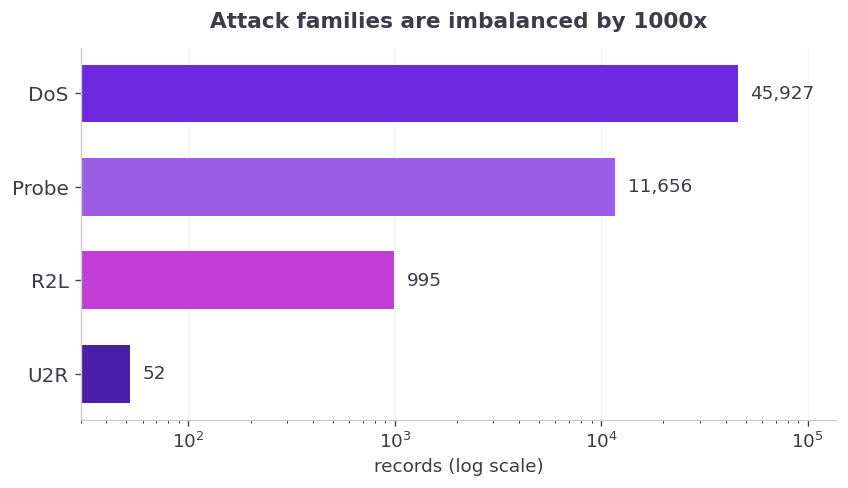

In [38]:
CSV_CANDIDATES = [
    "NSL_KDD_labeled.csv", "../../NSL_KDD_labeled.csv", "data/NSL_KDD_labeled.csv",
    r"D:\Python\AI\Code\ReservoirComputing\NSL_KDD_labeled.csv",
]
csv_path = next((p for p in CSV_CANDIDATES if Path(p).exists()), None)
assert csv_path, "NSL_KDD_labeled.csv not found"
df_raw = pd.read_csv(csv_path)

# ---- canonical NSL-KDD / KDD'99 taxonomy --------------------------------
# Every one of the 22 attack labels in this file maps to exactly one family;
# verified below with an assertion rather than trusted.
FAMILY_OF = {}
for fam, labels in {
    "DoS":   ["neptune", "smurf", "back", "teardrop", "pod", "land",
              "apache2", "udpstorm", "processtable", "mailbomb"],
    "Probe": ["satan", "ipsweep", "portsweep", "nmap", "mscan", "saint"],
    "R2L":   ["warezclient", "guess_passwd", "warezmaster", "imap", "ftp_write",
              "multihop", "phf", "spy", "sendmail", "named", "snmpgetattack",
              "snmpguess", "xlock", "xsnoop", "worm"],
    "U2R":   ["buffer_overflow", "rootkit", "loadmodule", "perl", "sqlattack",
              "xterm", "ps"],
}.items():
    for l in labels:
        FAMILY_OF[l] = fam

FAM_ORDER = ["DoS", "Probe", "R2L", "U2R"]

attack_labels = df_raw.label.value_counts().drop("normal")
missing = [l for l in attack_labels.index if l not in FAMILY_OF]
assert not missing, f"labels with no family mapping: {missing}"

fam_counts = (attack_labels.rename(index=FAMILY_OF)
              .groupby(level=0).sum().reindex(FAM_ORDER))
N_NORMAL = int((df_raw.label == "normal").sum())

print(f"normal: {N_NORMAL:,}")
print(fam_counts.to_string())
print(f"total attack: {int(fam_counts.sum()):,}")

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ypos = np.arange(len(FAM_ORDER))[::-1]
ax.barh(ypos, fam_counts.values, height=0.62,
        color=[FAM_COLORS[f] for f in FAM_ORDER])
for y, f in zip(ypos, FAM_ORDER):
    ax.text(fam_counts[f] * 1.15, y, f"{fam_counts[f]:,}",
            va="center", fontsize=11, color=INK)
ax.set_xscale("log")
ax.set_yticks(ypos); ax.set_yticklabels(FAM_ORDER, fontsize=12)
ax.set_xlabel("records (log scale)")
ax.set_xlim(30, fam_counts.max() * 3)
ax.set_title("Attack families are imbalanced by 1000x", pad=12)
ax.grid(axis="x", alpha=0.5); ax.set_axisbelow(True)
plt.tight_layout(); save(fig, "01_family_imbalance"); plt.show()

## 2. Supervised head, regrouped into real attack families

### Why this section exists

The supervised notebook ran two label schemes:

* `families6` — the five *most frequent individual labels* plus `other_attack`
* `all23` — every label as its own class

Neither is the standard **DoS / Probe / R2L / U2R** taxonomy, and `families6` is
actively misleading for a security audience: its `other_attack` bucket silently
merges **all 995 R2L rows and all 52 U2R rows** together with 2,067 DoS and
1,493 Probe rows. A strong `families6` macro-F1 therefore tells you nothing
about whether the system can flag a privilege-escalation attempt.

### What we do about it

We do **not** need to rerun anything. `all23` kept every label separate and
saved full 23x23 confusion matrices, so the family-level result is recovered
exactly by folding that matrix into 5x5 along the taxonomy. This is arithmetic
on the stored predictions, not a re-estimate.

In [39]:
def family_metrics(config, head, scheme="all23"):
    """Fold the stored 23x23 confusion matrix into normal + 4 families.

    Returns per-family precision/recall/F1/support. Exact, not approximate:
    it re-aggregates the same predictions the notebook already made.
    """
    rec = next(r for r in sup_rows
               if r["config"] == config and r["scheme"] == scheme)
    names = rec["class_names"]
    cm = np.load(SUP_ART / f"cm_{config}_{scheme}_{head}.npy").astype(float)

    group = ["normal"] + FAM_ORDER
    idx = [group.index("normal" if n == "normal" else FAMILY_OF[n]) for n in names]
    F = np.zeros((len(group), len(group)))
    for i in range(len(names)):
        for j in range(len(names)):
            F[idx[i], idx[j]] += cm[i, j]

    support = F.sum(1)
    recall  = np.divide(np.diag(F), support, out=np.zeros(len(group)), where=support > 0)
    pred    = F.sum(0)
    prec    = np.divide(np.diag(F), pred, out=np.zeros(len(group)), where=pred > 0)
    f1      = np.divide(2 * prec * recall, prec + recall,
                        out=np.zeros(len(group)), where=(prec + recall) > 0)
    return pd.DataFrame({"support": support.astype(int), "precision": prec,
                         "recall": recall, "f1": f1}, index=group), F


FAM = {}
for cfg in CONFIG_ORDER:
    for head in ("quantum", "dials"):
        try:
            FAM[(cfg, head)] = family_metrics(cfg, head)[0]
        except (StopIteration, FileNotFoundError):
            pass

print("=== family-level recall (fraction of that family correctly identified) ===")
tbl = pd.DataFrame({f"{c}_{h[0]}": FAM[(c, h)]["recall"]
                    for c in CONFIG_ORDER for h in ("quantum", "dials")
                    if (c, h) in FAM})
print(tbl.round(3).to_string())
print("\n=== family-level F1 ===")
tblf = pd.DataFrame({f"{c}_{h[0]}": FAM[(c, h)]["f1"]
                     for c in CONFIG_ORDER for h in ("quantum", "dials")
                     if (c, h) in FAM})
print(tblf.round(3).to_string())
print("\n(_q = quantum reservoir, _d = classical control)")

=== family-level recall (fraction of that family correctly identified) ===
        3p12m_q  3p12m_d  3p20m_q  3p20m_d  3p24m_q  3p24m_d  4p24m_q  4p24m_d
normal    0.920    0.485    0.954    0.572    0.959    0.628    0.963    0.628
DoS       0.999    0.993    1.000    0.995    1.000    0.995    1.000    0.995
Probe     0.994    0.974    0.993    0.977    0.993    0.977    0.995    0.977
R2L       0.933    0.963    0.950    0.963    0.940    0.956    0.940    0.956
U2R       0.875    0.875    0.750    0.812    0.688    0.812    0.750    0.812

=== family-level F1 ===
        3p12m_q  3p12m_d  3p20m_q  3p20m_d  3p24m_q  3p24m_d  4p24m_q  4p24m_d
normal    0.958    0.653    0.976    0.727    0.978    0.771    0.980    0.771
DoS       0.995    0.808    0.996    0.840    0.996    0.867    0.996    0.867
Probe     0.953    0.881    0.966    0.859    0.971    0.856    0.972    0.856
R2L       0.387    0.246    0.518    0.286    0.544    0.300    0.567    0.300
U2R       0.076    0.017    0.1

### 2.1 The headline figure — accuracy rises with reservoir size

**This is the main pitch chart.** Overall classification accuracy across the
four reservoir configurations, low to high, with the classical control as the
dim reference.

Accuracy here is measured at the **family level** (normal / DoS / Probe / R2L /
U2R): the fraction of all test traffic filed into the correct family. It is the
number a non-technical audience understands immediately, and unlike raw
"detection rate" it is *not* saturated — it moves from 95.6% to 97.9% while the
classical control sits 18 points below.

> **Not to be confused with detection rate.** "% of attacks caught" is flat at
> 99.85% for both arms and cannot be plotted honestly (section 2.1b). Accuracy
> counts false alarms on normal traffic too, which is exactly where the
> reservoir wins.

  saved pitch_figures\02_accuracy_vs_capacity.png


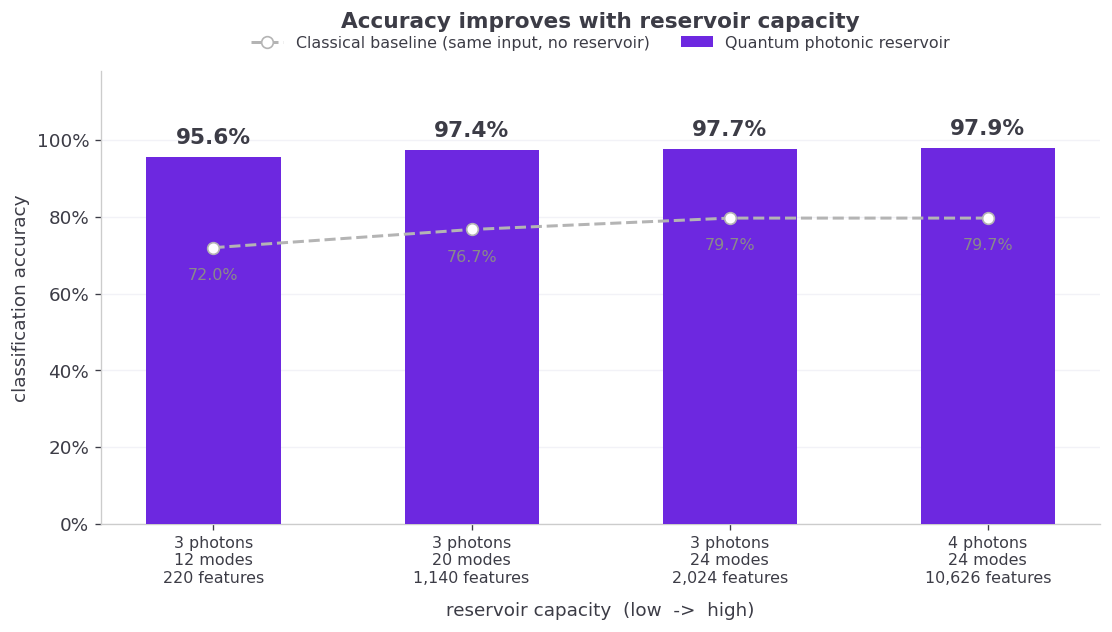

In [40]:
def overall_detection(config, head, scheme="all23"):
    """Fraction of attack rows NOT predicted as normal, from the stored CM."""
    rec = next(r for r in sup_rows
               if r["config"] == config and r["scheme"] == scheme)
    names = rec["class_names"]
    cm = np.load(SUP_ART / f"cm_{config}_{scheme}_{head}.npy").astype(float)
    ni = names.index("normal")
    atk = np.delete(cm, ni, axis=0)                 # true-attack rows
    caught = atk.sum() - atk[:, ni].sum()           # not predicted normal
    return caught / atk.sum()

det_q = [overall_detection(c, "quantum") for c in CONFIG_ORDER]
det_d = [overall_detection(c, "dials")   for c in CONFIG_ORDER]

def family_accuracy(config, head):
    """Overall accuracy over normal + the 4 families (diagonal / total)."""
    _, F = family_metrics(config, head)
    return np.trace(F) / F.sum()

acc_q = [family_accuracy(c, "quantum") for c in CONFIG_ORDER]
acc_d = [family_accuracy(c, "dials")   for c in CONFIG_ORDER]

# macro F1 kept for the two-heads summary and the numbers report
mf1_q = [FAM[(c, "quantum")].loc[FAM_ORDER, "f1"].mean() for c in CONFIG_ORDER]
mf1_d = [FAM[(c, "dials")].loc[FAM_ORDER, "f1"].mean()   for c in CONFIG_ORDER]

x = np.arange(len(CONFIG_ORDER))
fig, ax = plt.subplots(figsize=(9.4, 5.4))

BAR_W = 0.52
ax.bar(x, acc_q, BAR_W, color=PINK, zorder=3,
       label="Quantum photonic reservoir")
# classical control: a dim flat reference, deliberately quiet
ax.plot(x, acc_d, color=DIM, lw=1.8, ls="--", marker="o", ms=7,
        markerfacecolor="white", markeredgecolor=DIM, zorder=4,
        label="Classical baseline (same input, no reservoir)")

for xi, v in zip(x, acc_q):
    ax.annotate(f"{v*100:.1f}%", (xi, v), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=13,
                fontweight="bold", color=INK, zorder=5)
for xi, v in zip(x, acc_d):
    ax.annotate(f"{v*100:.1f}%", (xi, v), textcoords="offset points",
                xytext=(0, -19), ha="center", fontsize=9.5, color=DIM_DARK)

ax.set_xticks(x)
ax.set_xticklabels([f"{CONFIG_LABEL[c]}\n{READOUT_DIM[c]:,} Fock states"
                    for c in CONFIG_ORDER], fontsize=9.5)
ax.set_ylabel("classification accuracy")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0, 1.18)          # headroom so the legend never sits over a bar
ax.set_xlabel("reservoir capacity  (low  ->  high)", labelpad=10)
ax.set_title("Accuracy improves with reservoir capacity", pad=26)
ax.grid(axis="y", alpha=0.6); ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.11), ncol=2, fontsize=9.5)
plt.tight_layout(); save(fig, "02_accuracy_vs_capacity"); plt.show()

### 2.1a Accuracy on a log scale — the narrow-range fix

Accuracy sits in a narrow band (95.6%–97.9%), so a linear axis flattens the
differences. The standard fix is to plot the **error rate** — `100% − accuracy` —
on a **log10 axis**.

Why error rate rather than `log10(accuracy)` directly: the log of a number close
to 1 is close to 0, so `log10(0.955)` and `log10(0.979)` differ by only 0.01 and
the chart stays just as flat. Taking the *complement* first turns the same data
into **1.1 decades** of range, where the improvement is unmissable.

This is the honest way to expand a narrow high-accuracy range, and it is the
convention in error-rate reporting. Read it as **lower = better**, and note that
each gridline is a 10x reduction in mistakes.

  saved pitch_figures\02a_error_rate_log.png


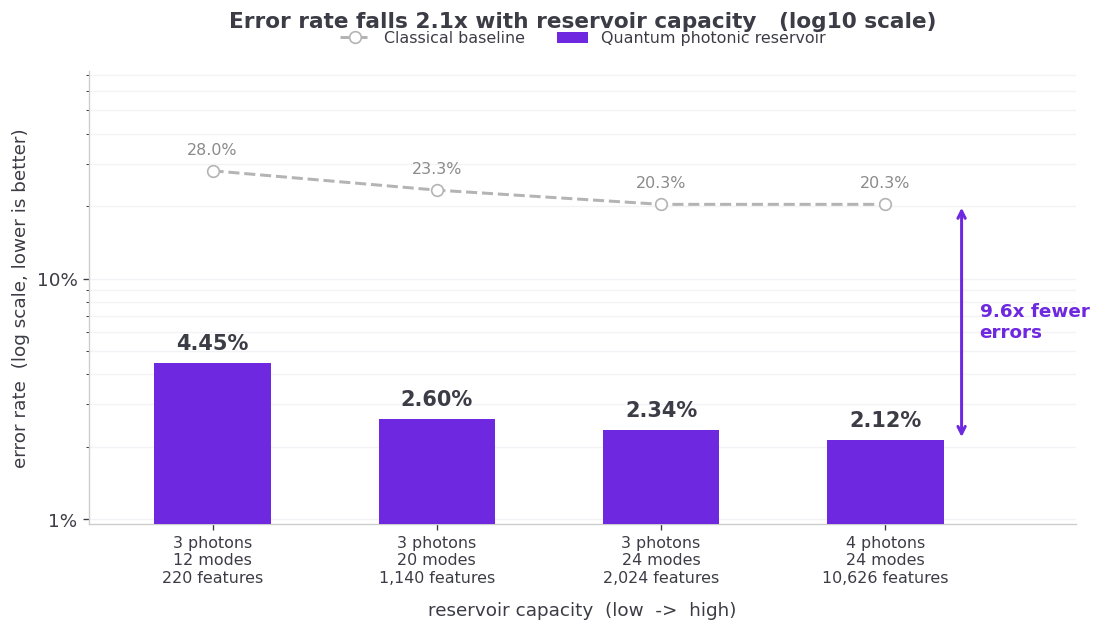

In [41]:
err_q = [(1 - a) * 100 for a in acc_q]
err_d = [(1 - a) * 100 for a in acc_d]

fig, ax = plt.subplots(figsize=(9.4, 5.4))
ax.bar(x, err_q, BAR_W, color=PINK, zorder=3,
       label="Quantum photonic reservoir")
ax.plot(x, err_d, color=DIM, lw=1.8, ls="--", marker="o", ms=7,
        markerfacecolor="white", markeredgecolor=DIM, zorder=4,
        label="Classical baseline")

ax.set_yscale("log")
for xi, v in zip(x, err_q):
    ax.annotate(f"{v:.2f}%", (xi, v), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=12.5,
                fontweight="bold", color=INK, zorder=5)
for xi, v in zip(x, err_d):
    ax.annotate(f"{v:.1f}%", (xi, v), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=9.5, color=DIM_DARK)

# call out the headline ratio at the best config
ratio = err_d[-1] / err_q[-1]
ax.annotate("", xy=(x[-1] + 0.34, err_q[-1]), xytext=(x[-1] + 0.34, err_d[-1]),
            arrowprops=dict(arrowstyle="<->", color=PINK, lw=1.8))
ax.text(x[-1] + 0.42, np.sqrt(err_q[-1] * err_d[-1]),
        f"{ratio:.1f}x fewer\nerrors", color=PINK, fontsize=11,
        fontweight="bold", va="center")

drop = err_q[0] / err_q[-1]
ax.set_xticks(x)
ax.set_xticklabels([f"{CONFIG_LABEL[c]}\n{READOUT_DIM[c]:,} Fock states"
                    for c in CONFIG_ORDER], fontsize=9.5)
ax.set_ylabel("error rate  (log scale, lower is better)")
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(
    lambda v, _: f"{v:g}%"))
ax.set_xlim(-0.55, len(CONFIG_ORDER) - 0.15)
# headroom above the classical line and below the smallest bar, so the
# annotations sit in empty space rather than over the marks
ax.set_ylim(min(err_q) * 0.45, max(err_d) * 2.6)
ax.set_xlabel("reservoir capacity  (low  ->  high)", labelpad=10)
ax.set_title(f"Error rate falls {drop:.1f}x with reservoir capacity   (log10 scale)",
             pad=26)
ax.grid(axis="y", alpha=0.6, which="both"); ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.12), ncol=2, fontsize=9.5)
plt.tight_layout(); save(fig, "02a_error_rate_log"); plt.show()

### 2.1b The saturated metric, shown honestly

Raw detection rate on a **full 0–100% axis**, which is the only fair way to draw
it. Both arms sit on the ceiling; the lines are indistinguishable. This is not a
weakness of the method — it means the easy 97% of traffic is a solved problem,
and it is why the deck leads with accuracy instead.

Use this slide if someone asks "but what's your detection rate?" — the answer is
99.9%, and the interesting work is elsewhere.

  saved pitch_figures\02b_detection_saturated.png


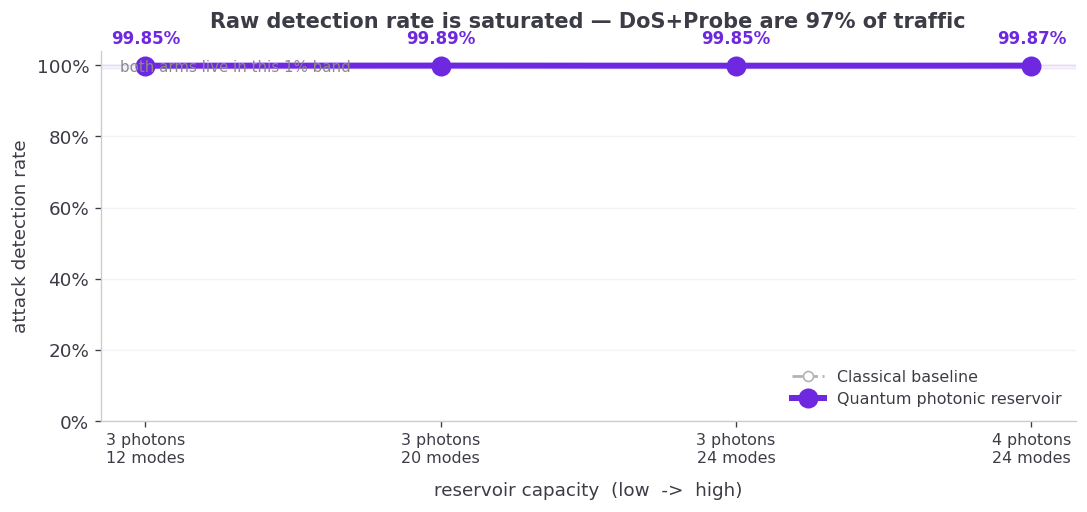

In [42]:
fig, ax = plt.subplots(figsize=(9.2, 4.4))
ax.plot(x, det_d, color=DIM, lw=1.7, ls="--", marker="o", ms=6,
        markerfacecolor="white", markeredgecolor=DIM,
        label="Classical baseline", zorder=2)
ax.plot(x, det_q, color=PINK, lw=3.6, marker="o", ms=11,
        label="Quantum photonic reservoir", zorder=3)
ax.set_ylim(0, 1.04)
ax.axhspan(0.99, 1.0, color=PINK, alpha=0.06)
ax.text(0.02, 0.995, "both arms live in this 1% band",
        transform=ax.get_yaxis_transform(), fontsize=9,
        color=DIM_DARK, va="center")
for xi, v in zip(x, det_q):
    ax.annotate(f"{v*100:.2f}%", (xi, v), textcoords="offset points",
                xytext=(0, 13), ha="center", fontsize=10,
                fontweight="bold", color=PINK)
ax.set_xticks(x)
ax.set_xticklabels([CONFIG_LABEL[c] for c in CONFIG_ORDER], fontsize=9.5)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("attack detection rate")
ax.set_xlabel("reservoir capacity  (low  ->  high)", labelpad=10)
ax.set_title("Raw detection rate is saturated — DoS+Probe are 97% of traffic",
             pad=14, fontsize=12.5)
ax.grid(axis="y", alpha=0.6); ax.set_axisbelow(True)
ax.legend(loc="lower right", fontsize=9.5)
plt.tight_layout(); save(fig, "02b_detection_saturated"); plt.show()

### 2.2 Per-class accuracy — where the reservoir earns its keep

The same story broken out per class. The revealing panel is **normal**: the
classical control only gets 62.8% of normal traffic right, so it floods the
analyst with false alarms, while the quantum arm reaches 96.3%. DoS and Probe
are near-perfect for both — that is the saturated part of the problem.

  saved pitch_figures\03_accuracy_by_family.png


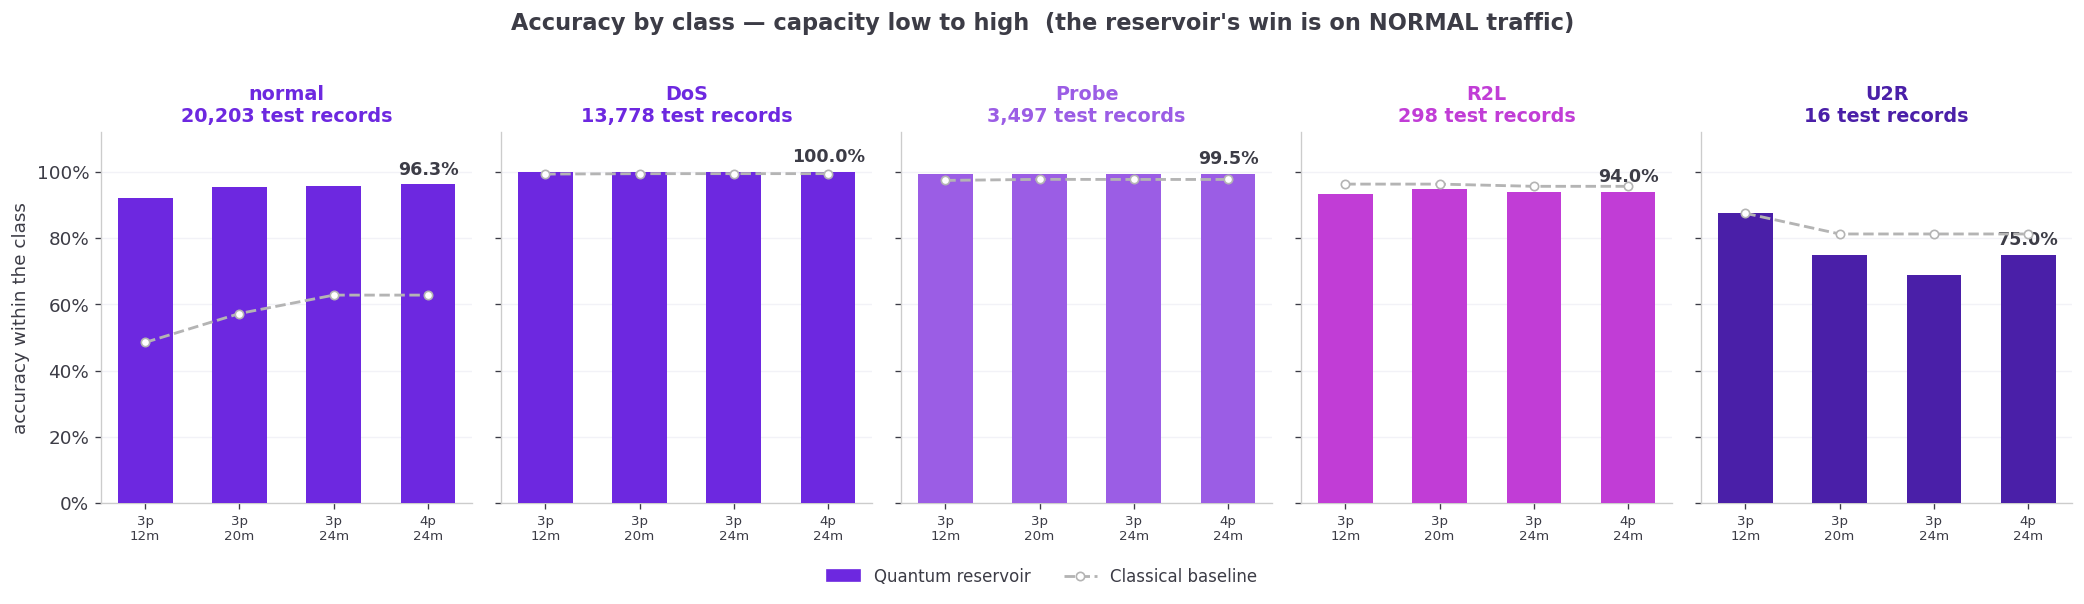

  saved pitch_figures\03b_rare_attacks.png


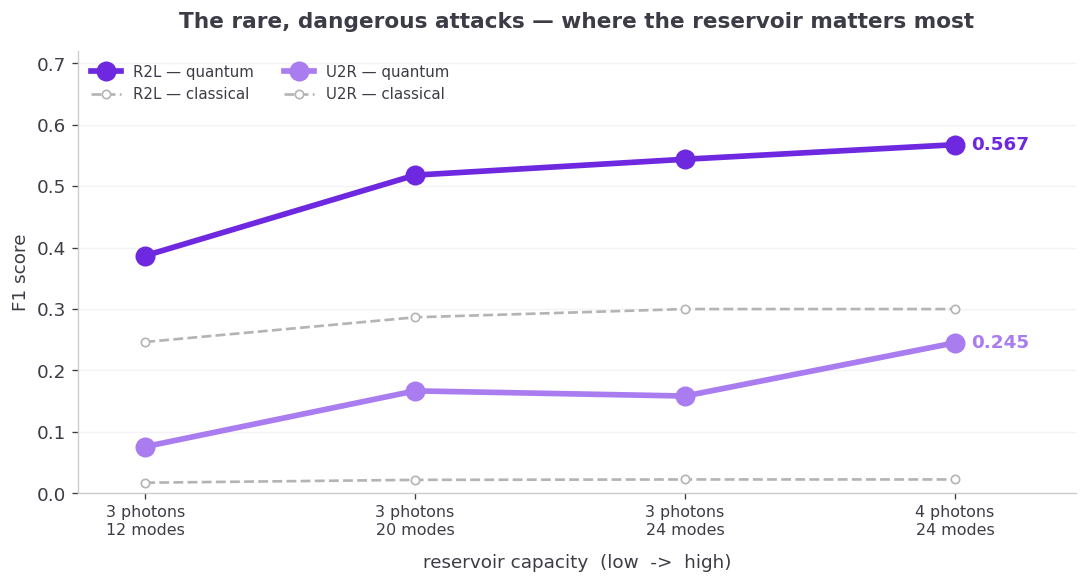

In [43]:
fig, axes = plt.subplots(1, 5, figsize=(17.5, 4.5), sharey=True)
PANELS = ["normal"] + FAM_ORDER
for ax, fam in zip(axes, PANELS):
    rq = [FAM[(c, "quantum")].loc[fam, "recall"] for c in CONFIG_ORDER]
    rd = [FAM[(c, "dials")].loc[fam, "recall"]   for c in CONFIG_ORDER]
    col = PINK if fam == "normal" else FAM_COLORS[fam]
    ax.bar(x, rq, 0.58, color=col, zorder=3)
    ax.plot(x, rd, color=DIM, lw=1.7, ls="--", marker="o", ms=5,
            markerfacecolor="white", markeredgecolor=DIM, zorder=4)
    n = int(FAM[(CONFIG_ORDER[0], "quantum")].loc[fam, "support"])
    ax.set_title(f"{fam}\n{n:,} test records", fontsize=11.5, color=col)
    ax.annotate(f"{rq[-1]*100:.1f}%", (x[-1], rq[-1]),
                textcoords="offset points", xytext=(0, 6), ha="center",
                fontsize=10.5, fontweight="bold", color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels([c.replace("p", "p\n") for c in CONFIG_ORDER], fontsize=8)
    ax.grid(axis="y", alpha=0.6); ax.set_axisbelow(True)
    ax.set_ylim(0, 1.12)
axes[0].set_ylabel("accuracy within the class")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
fig.legend(handles=[
    mpl.patches.Patch(color=PINK, label="Quantum reservoir"),
    plt.Line2D([], [], color=DIM, lw=1.7, ls="--", marker="o", ms=5,
               markerfacecolor="white", label="Classical baseline")],
    loc="lower center", ncol=2, fontsize=10, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("Accuracy by class — capacity low to high  "
             "(the reservoir's win is on NORMAL traffic)",
             y=1.02, fontsize=13.5, fontweight="bold")
plt.tight_layout(); save(fig, "03_accuracy_by_family"); plt.show()

# ---- the rare-attack story, on its own slide -----------------------------
fig, ax = plt.subplots(figsize=(9.2, 5.0))
for fam, style in [("R2L", dict(lw=3.4, ms=11)), ("U2R", dict(lw=3.4, ms=11))]:
    vq = [FAM[(c, "quantum")].loc[fam, "f1"] for c in CONFIG_ORDER]
    vd = [FAM[(c, "dials")].loc[fam, "f1"]   for c in CONFIG_ORDER]
    col = PINK if fam == "R2L" else PINK_SOFT
    ax.plot(x, vq, color=col, marker="o", label=f"{fam} — quantum", **style)
    ax.plot(x, vd, color=DIM, lw=1.6, ls="--", marker="o", ms=5,
            markerfacecolor="white", markeredgecolor=DIM,
            label=f"{fam} — classical")
    ax.annotate(f"{vq[-1]:.3f}", (x[-1], vq[-1]), textcoords="offset points",
                xytext=(10, 0), fontsize=11, fontweight="bold", color=col,
                va="center")
ax.set_xticks(x)
ax.set_xticklabels([CONFIG_LABEL[c] for c in CONFIG_ORDER], fontsize=9.5)
ax.set_ylabel("F1 score"); ax.set_ylim(0, 0.72)
ax.set_xlim(-0.25, len(CONFIG_ORDER) - 0.55)
ax.set_xlabel("reservoir capacity  (low  ->  high)", labelpad=10)
ax.set_title("The rare, dangerous attacks — where the reservoir matters most",
             pad=14)
ax.grid(axis="y", alpha=0.6); ax.set_axisbelow(True)
ax.legend(fontsize=9, loc="upper left", ncol=2)
plt.tight_layout(); save(fig, "03b_rare_attacks"); plt.show()

### 2.3 The honest slide — recall is not the whole story

R2L and U2R are *caught* at high rates, but at low **precision**: the model
raises many false accusations to find them. On a pitch deck this belongs on the
same slide as the win, not hidden — it is also the natural lead-in to the
novelty head, which exists precisely because rare-attack precision is hard.

  saved pitch_figures\04_recall_vs_precision.png


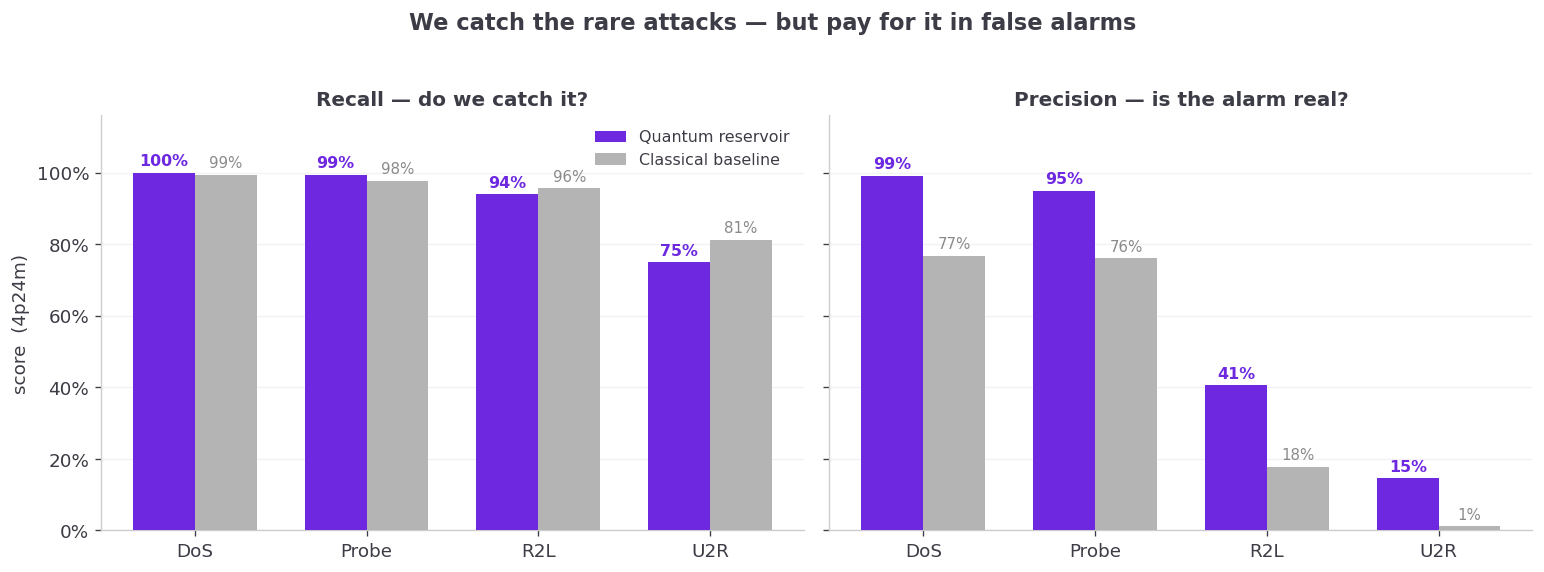

In [44]:
best = "4p24m"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
w = 0.36
for ax, (met, title) in zip(axes, [("recall", "Recall — do we catch it?"),
                                   ("precision", "Precision — is the alarm real?")]):
    vq = [FAM[(best, "quantum")].loc[f, met] for f in FAM_ORDER]
    vd = [FAM[(best, "dials")].loc[f, met]   for f in FAM_ORDER]
    xf = np.arange(len(FAM_ORDER))
    ax.bar(xf - w/2, vq, w, color=PINK, label="Quantum reservoir", zorder=3)
    ax.bar(xf + w/2, vd, w, color=DIM, label="Classical baseline", zorder=3)
    for xi, v in zip(xf - w/2, vq):
        ax.text(xi, v + 0.02, f"{v*100:.0f}%", ha="center", fontsize=9.5,
                color=PINK, fontweight="bold")
    for xi, v in zip(xf + w/2, vd):
        ax.text(xi, v + 0.02, f"{v*100:.0f}%", ha="center", fontsize=9,
                color=DIM_DARK)
    ax.set_xticks(xf); ax.set_xticklabels(FAM_ORDER, fontsize=11)
    ax.set_title(title, fontsize=12); ax.set_ylim(0, 1.16)
    ax.grid(axis="y", alpha=0.6); ax.set_axisbelow(True)
axes[0].set_ylabel(f"score  ({best})")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].legend(loc="upper right", fontsize=9.5)
fig.suptitle("We catch the rare attacks — but pay for it in false alarms",
             y=1.03, fontsize=13.5, fontweight="bold")
plt.tight_layout(); save(fig, "04_recall_vs_precision"); plt.show()

### 2.4 Attack classification quality — the confusion matrix, family level

What gets mistaken for what, at the best config. Row-normalised: each row reads
"of this true family, where did it go?". The diagonal is what we want; the
`normal` column is misses and the `normal` row is false alarms.

  saved pitch_figures\05_family_confusion.png


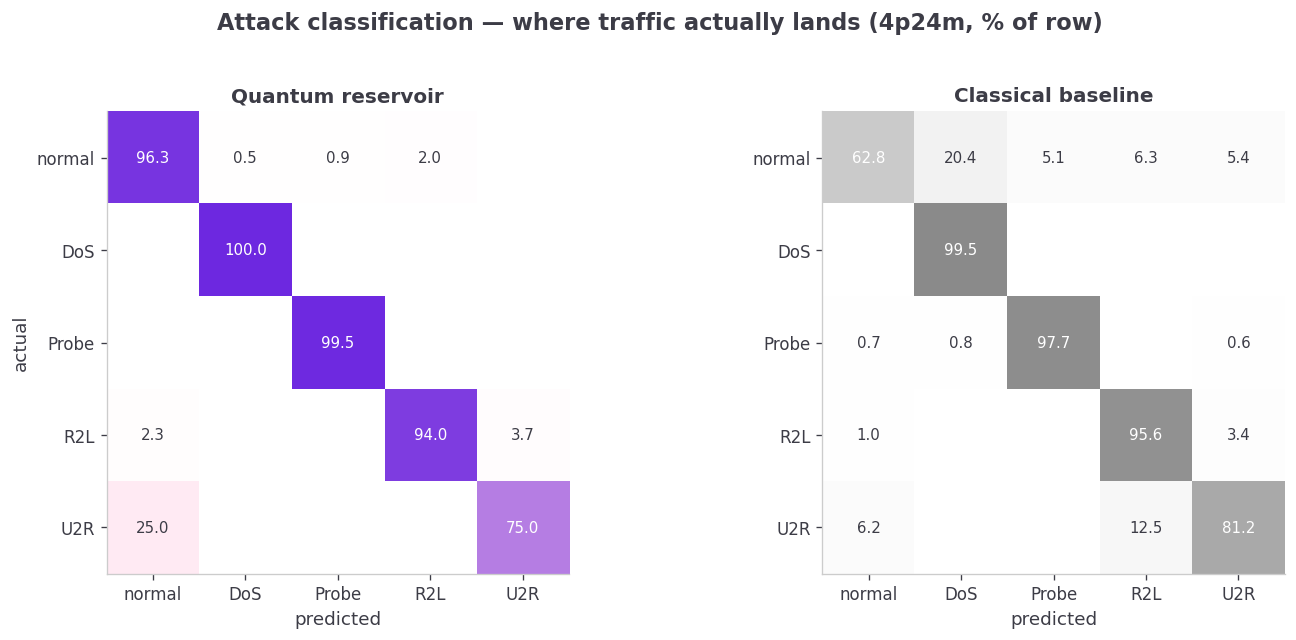

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
group = ["normal"] + FAM_ORDER
for ax, head, title in [(axes[0], "quantum", "Quantum reservoir"),
                        (axes[1], "dials", "Classical baseline")]:
    _, F = family_metrics(best, head)
    Fn = F / np.maximum(F.sum(1, keepdims=True), 1)
    cmap = mpl.colors.LinearSegmentedColormap.from_list(
        "pinkish", ["#FFFFFF", "#FFD6E8", PINK]) if head == "quantum" else \
        mpl.colors.LinearSegmentedColormap.from_list(
        "greyish", ["#FFFFFF", "#E0E0E0", DIM_DARK])
    ax.imshow(Fn, cmap=cmap, vmin=0, vmax=1)
    for i in range(len(group)):
        for j in range(len(group)):
            if Fn[i, j] > 0.005:
                ax.text(j, i, f"{Fn[i,j]*100:.1f}", ha="center", va="center",
                        fontsize=9,
                        color="white" if Fn[i, j] > 0.6 else INK)
    ax.set_xticks(range(len(group))); ax.set_xticklabels(group, fontsize=10)
    ax.set_yticks(range(len(group))); ax.set_yticklabels(group, fontsize=10)
    ax.set_xlabel("predicted"); ax.set_title(title, fontsize=12)
    ax.set_ylabel("actual" if head == "quantum" else "")
fig.suptitle(f"Attack classification — where traffic actually lands ({best}, % of row)",
             y=1.02, fontsize=13.5, fontweight="bold")
plt.tight_layout(); save(fig, "05_family_confusion"); plt.show()

### 2.5 Fine-grained classification — all 23 attack types

For the technical appendix: per-class F1 at the best config, coloured by family.
This is the slide that answers "but can it tell *which* attack?".

  saved pitch_figures\06_per_attack_f1.png


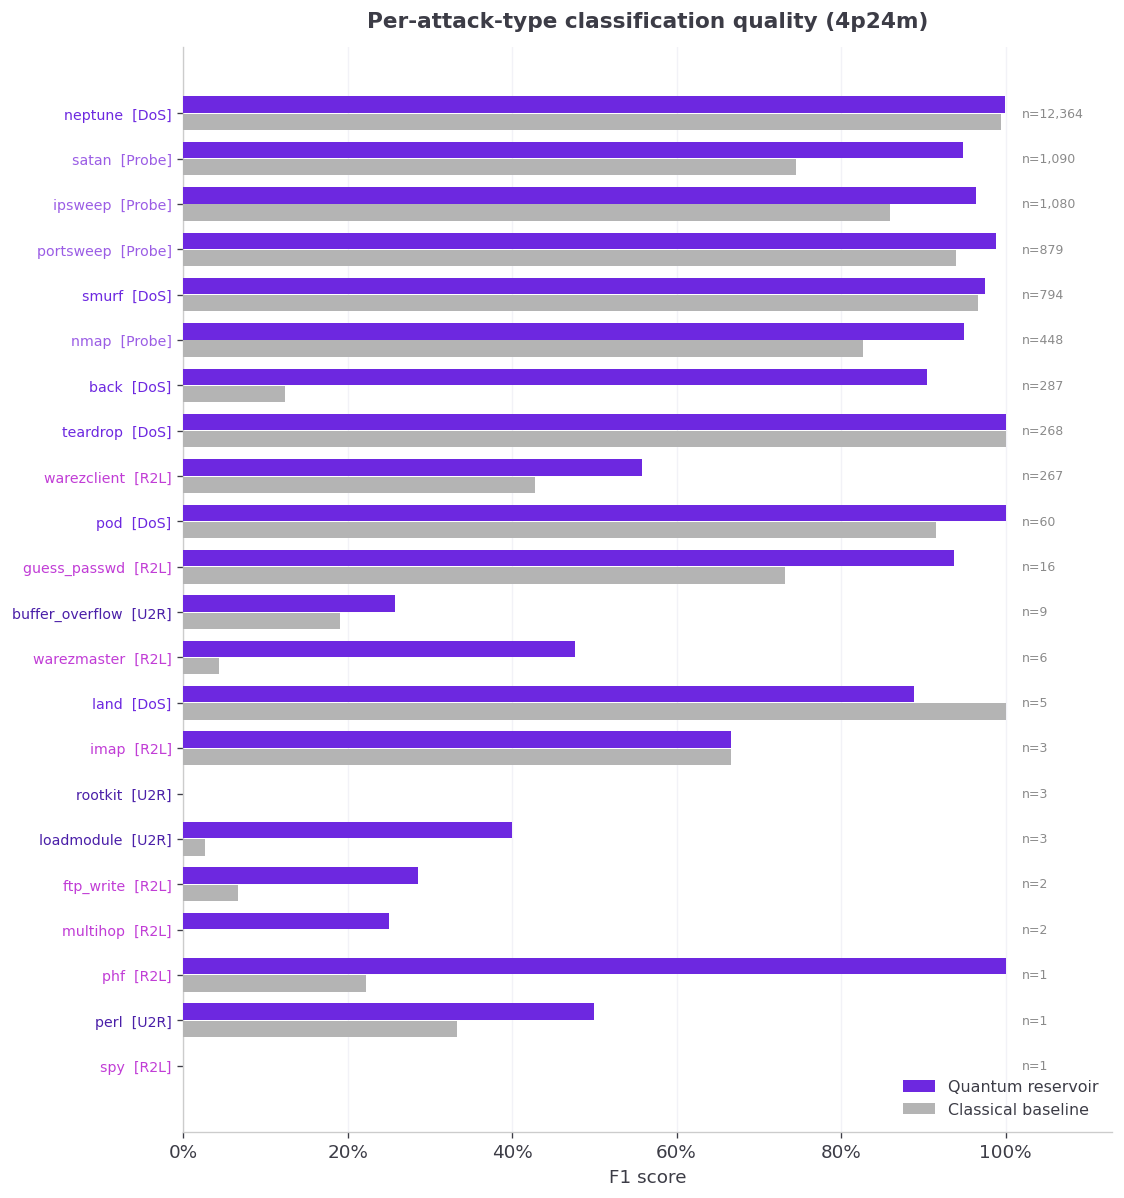

In [46]:
rec = next(r for r in sup_rows if r["config"] == best and r["scheme"] == "all23")
pc_q = rec["heads"]["quantum"]["per_class"]
pc_d = rec["heads"]["dials"]["per_class"]
items = [(n, pc_q[n]["f1"], pc_d[n]["f1"], pc_q[n]["support"])
         for n in rec["class_names"] if n != "normal"]
items.sort(key=lambda t: t[3], reverse=True)

names = [t[0] for t in items]
ypos = np.arange(len(names))[::-1]
fig, ax = plt.subplots(figsize=(9.5, 0.36 * len(names) + 2.2))
ax.barh(ypos + 0.19, [t[1] for t in items], 0.36, color=PINK,
        label="Quantum reservoir", zorder=3)
ax.barh(ypos - 0.19, [t[2] for t in items], 0.36, color=DIM,
        label="Classical baseline", zorder=3)
for y, t in zip(ypos, items):
    ax.text(1.02, y, f"n={t[3]:,}", va="center", fontsize=7.5, color=DIM_DARK)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{n}  [{FAMILY_OF[n]}]" for n in names], fontsize=8.5)
for lbl, n in zip(ax.get_yticklabels(), names):
    lbl.set_color(FAM_COLORS[FAMILY_OF[n]])
ax.set_xlim(0, 1.13); ax.set_xlabel("F1 score")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title(f"Per-attack-type classification quality ({best})", pad=12)
ax.grid(axis="x", alpha=0.6); ax.set_axisbelow(True)
ax.legend(loc="lower right", fontsize=9.5)
plt.tight_layout(); save(fig, "06_per_attack_f1"); plt.show()

### 2.6 False alarms — the operational cost

A security team lives or dies by false-alarm volume. This is the supervised
head's false-alarm rate on normal traffic, which the reservoir cuts sharply.

  saved pitch_figures\07_false_alarms.png


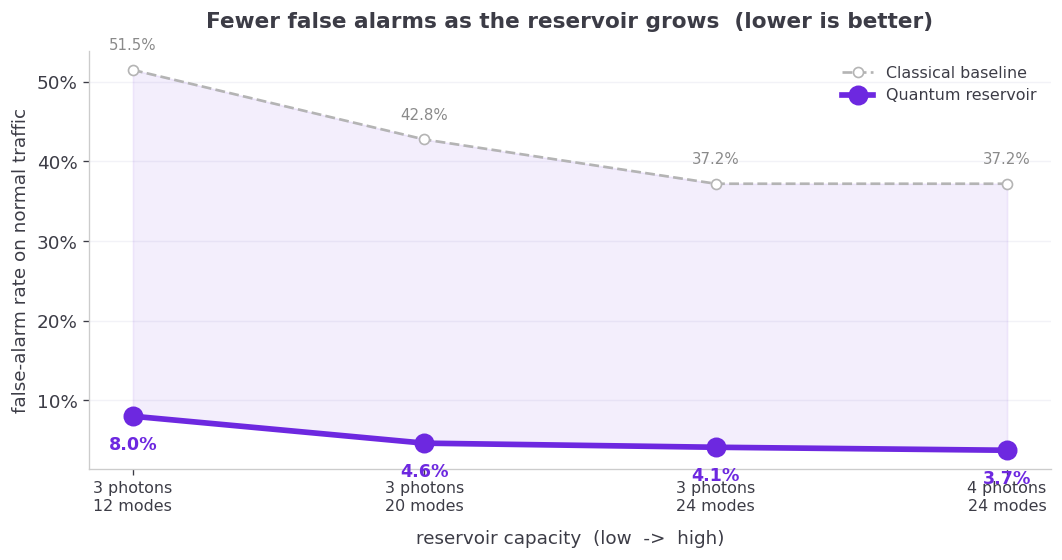

In [47]:
OPS = pd.read_csv(Path(SUP_RUN).parent / "metrics_operational.csv")
o = OPS[OPS["scheme"] == "all23"].set_index(["config", "head"])
assert len(o), "no all23 rows in metrics_operational.csv"
fa_q = [o.loc[(c, "quantum"), "false_alarm"] for c in CONFIG_ORDER]
fa_d = [o.loc[(c, "dials"),   "false_alarm"] for c in CONFIG_ORDER]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(x, fa_d, color=DIM, lw=1.6, ls="--", marker="o", ms=6,
        markerfacecolor="white", markeredgecolor=DIM,
        label="Classical baseline", zorder=2)
ax.plot(x, fa_q, color=PINK, lw=3.4, marker="o", ms=11,
        label="Quantum reservoir", zorder=3)
ax.fill_between(x, fa_q, fa_d, color=PINK, alpha=0.08, zorder=1)
for xi, v in zip(x, fa_q):
    ax.annotate(f"{v*100:.1f}%", (xi, v), textcoords="offset points",
                xytext=(0, -20), ha="center", fontsize=10.5,
                fontweight="bold", color=PINK)
for xi, v in zip(x, fa_d):
    ax.annotate(f"{v*100:.1f}%", (xi, v), textcoords="offset points",
                xytext=(0, 12), ha="center", fontsize=9, color=DIM_DARK)
ax.set_xticks(x)
ax.set_xticklabels([CONFIG_LABEL[c] for c in CONFIG_ORDER], fontsize=9.5)
ax.set_ylabel("false-alarm rate on normal traffic")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("reservoir capacity  (low  ->  high)", labelpad=10)
ax.set_title("Fewer false alarms as the reservoir grows  (lower is better)", pad=14)
ax.grid(axis="y", alpha=0.6); ax.set_axisbelow(True)
ax.legend(fontsize=9.5)
plt.tight_layout(); save(fig, "07_false_alarms"); plt.show()

## 3. Novelty head — zero-day detection

A different question, and an honest one: this model is trained on **normal
traffic only** and has never seen any attack. Every attack type is therefore
genuinely unseen.

The result runs the *opposite* way to the supervised head — smaller reservoirs
do better, because a distance-based novelty detector suffers from the curse of
dimensionality where a linear classifier benefits from extra dimensions.

  saved pitch_figures\08_zeroday_capacity.png


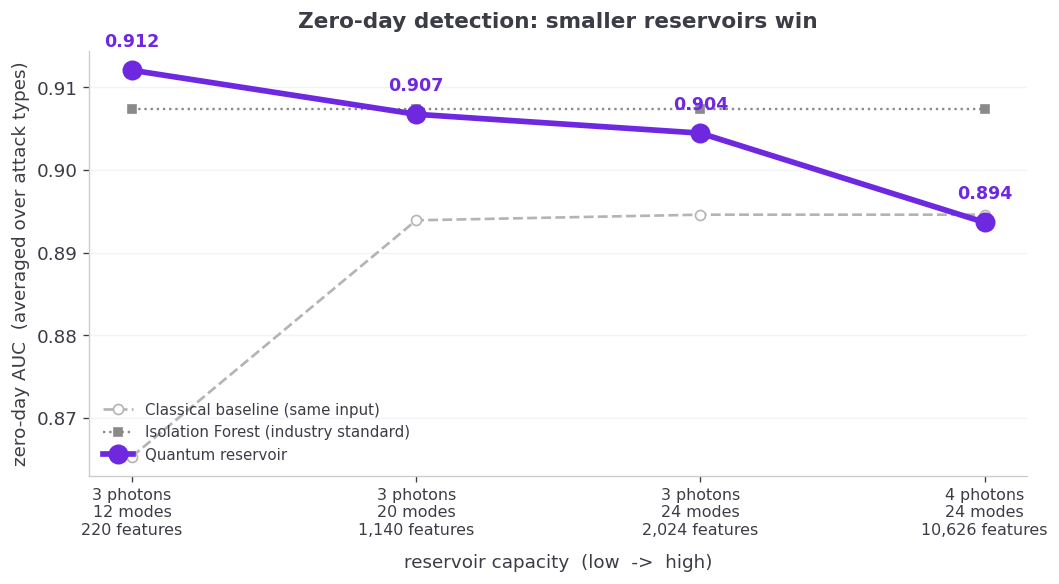

In [48]:
NOVD = pd.read_csv(Path(NOV_RUN).parent / "metrics_flat.csv")
nq = NOVD[NOVD.detector == "NOV_q"].set_index("config").reindex(CONFIG_ORDER)
nd = NOVD[NOVD.detector == "NOV_dials"].set_index("config").reindex(CONFIG_ORDER)
ni = NOVD[NOVD.detector == "IForest"].set_index("config").reindex(CONFIG_ORDER)

fig, ax = plt.subplots(figsize=(9, 5.0))
ax.plot(x, nd["auc_macro_big"], color=DIM, lw=1.6, ls="--", marker="o", ms=6,
        markerfacecolor="white", markeredgecolor=DIM,
        label="Classical baseline (same input)", zorder=2)
ax.plot(x, ni["auc_macro_big"], color=DIM_DARK, lw=1.4, ls=":", marker="s", ms=5,
        label="Isolation Forest (industry standard)", zorder=2)
ax.plot(x, nq["auc_macro_big"], color=PINK, lw=3.4, marker="o", ms=11,
        label="Quantum reservoir", zorder=4)
for xi, v in zip(x, nq["auc_macro_big"]):
    ax.annotate(f"{v:.3f}", (xi, v), textcoords="offset points",
                xytext=(0, 14), ha="center", fontsize=10.5,
                fontweight="bold", color=PINK)
ax.set_xticks(x)
ax.set_xticklabels([f"{CONFIG_LABEL[c]}\n{READOUT_DIM[c]:,} Fock states"
                    for c in CONFIG_ORDER], fontsize=9.5)
ax.set_ylabel("zero-day AUC  (averaged over attack types)")
ax.set_xlabel("reservoir capacity  (low  ->  high)", labelpad=10)
ax.set_title("Zero-day detection: smaller reservoirs win", pad=14)
ax.grid(axis="y", alpha=0.6); ax.set_axisbelow(True)
ax.legend(fontsize=9, loc="lower left")
plt.tight_layout(); save(fig, "08_zeroday_capacity"); plt.show()

### 3.1 Zero-day detection by family

Which *kinds* of never-before-seen attack does the novelty head catch? Averaged
over the attack types in each family that have enough rows to measure.

  saved pitch_figures\09_zeroday_by_family.png


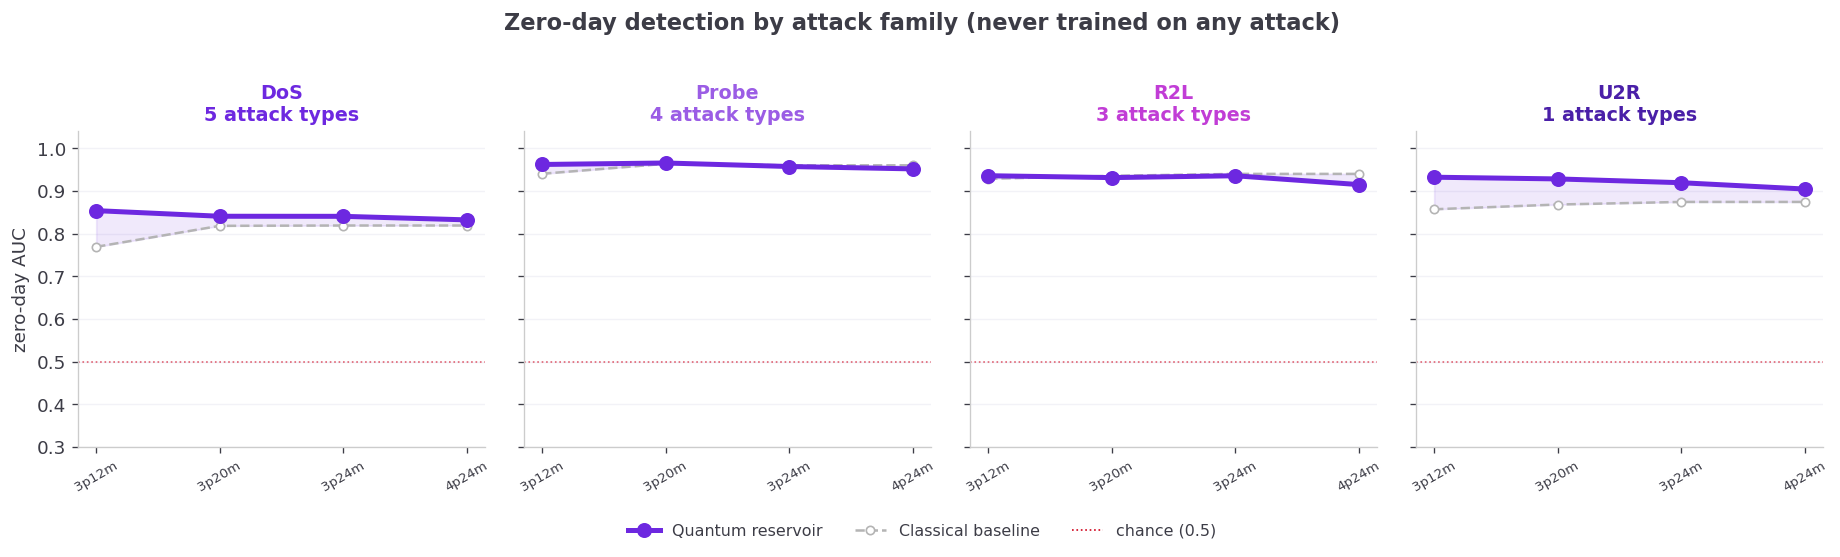

In [49]:
NPA = pd.read_csv(Path(NOV_RUN).parent / "metrics_per_attack.csv")
NPA["family"] = NPA["attack"].map(FAMILY_OF)
MIN_N = 20
big = NPA[NPA.n >= MIN_N]

famauc = (big[big.detector == "NOV_q"]
          .groupby(["config", "family"])["auc"].mean().unstack()
          .reindex(CONFIG_ORDER)[FAM_ORDER])
famauc_d = (big[big.detector == "NOV_dials"]
            .groupby(["config", "family"])["auc"].mean().unstack()
            .reindex(CONFIG_ORDER)[FAM_ORDER])

fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.1), sharey=True)
for ax, fam in zip(axes, FAM_ORDER):
    ax.plot(x, famauc_d[fam], color=DIM, lw=1.5, ls="--", marker="o", ms=5,
            markerfacecolor="white", markeredgecolor=DIM, zorder=2)
    ax.plot(x, famauc[fam], color=PINK, lw=3.0, marker="o", ms=8, zorder=3)
    ax.fill_between(x, famauc_d[fam], famauc[fam], color=PINK, alpha=0.10)
    ax.axhline(0.5, color="#D0021B", ls=":", lw=1, alpha=0.6)
    ntypes = big[(big.family == fam) & (big.detector == "NOV_q") &
                 (big.config == CONFIG_ORDER[0])].shape[0]
    ax.set_title(f"{fam}\n{ntypes} attack types", fontsize=11.5,
                 color=FAM_COLORS[fam])
    ax.set_xticks(x); ax.set_xticklabels(CONFIG_ORDER, fontsize=8, rotation=30)
    ax.grid(axis="y", alpha=0.6); ax.set_axisbelow(True); ax.set_ylim(0.3, 1.04)
axes[0].set_ylabel("zero-day AUC")
fig.legend(handles=[
    plt.Line2D([], [], color=PINK, lw=3, marker="o", ms=8, label="Quantum reservoir"),
    plt.Line2D([], [], color=DIM, lw=1.5, ls="--", marker="o", ms=5,
               markerfacecolor="white", label="Classical baseline"),
    plt.Line2D([], [], color="#D0021B", ls=":", lw=1, label="chance (0.5)")],
    loc="lower center", ncol=3, fontsize=9.5, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Zero-day detection by attack family (never trained on any attack)",
             y=1.02, fontsize=13.5, fontweight="bold")
plt.tight_layout(); save(fig, "09_zeroday_by_family"); plt.show()

### 3.2 The two heads answer different questions

The summary slide. Same fixed quantum reservoir, two heads, opposite capacity
preferences — which is exactly why the system ships both.

  saved pitch_figures\10_two_heads.png


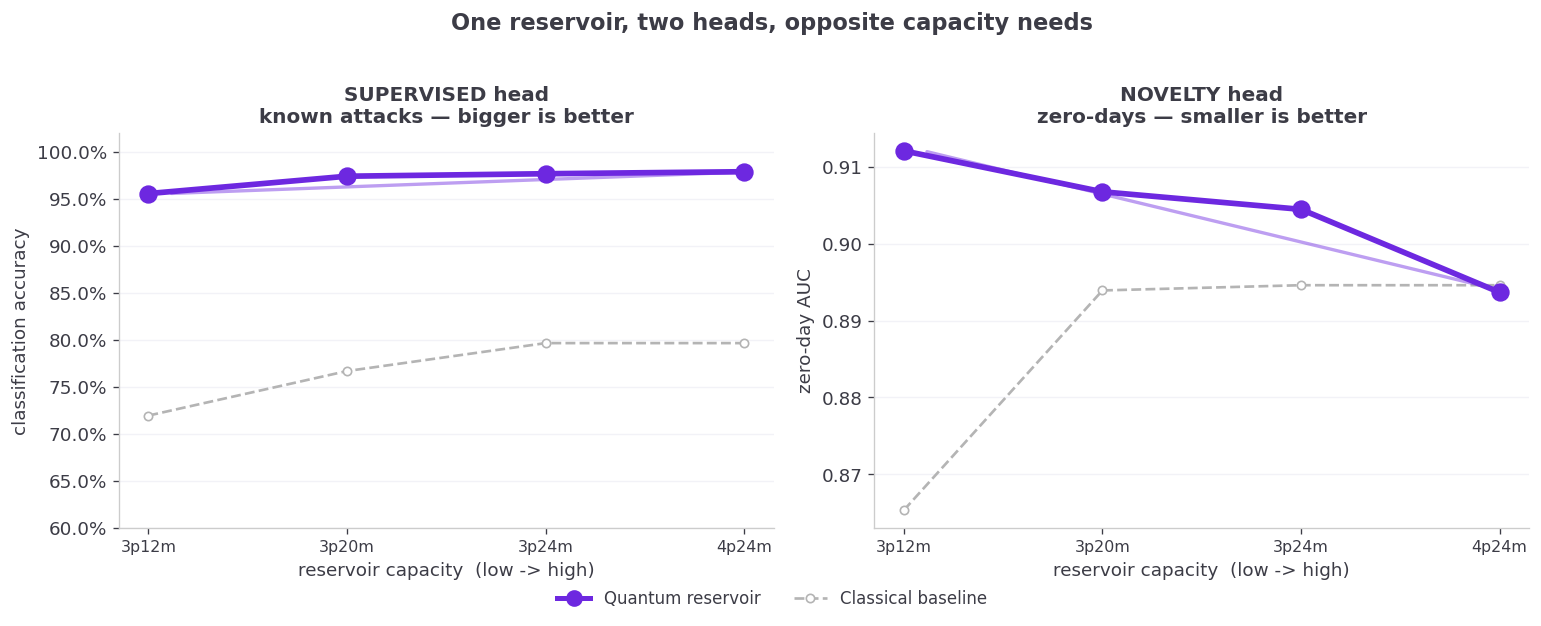

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# left: supervised -- rises
ax = axes[0]
ax.plot(x, acc_d, color=DIM, lw=1.6, ls="--", marker="o", ms=5,
        markerfacecolor="white", markeredgecolor=DIM)
ax.plot(x, acc_q, color=PINK, lw=3.4, marker="o", ms=10)
ax.set_title("SUPERVISED head\nknown attacks — bigger is better", fontsize=12)
ax.set_ylabel("classification accuracy")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0.6, 1.02)
ax.annotate("", xy=(3.05, acc_q[-1]), xytext=(0.1, acc_q[0]),
            arrowprops=dict(arrowstyle="->", color=PINK, lw=2, alpha=0.45))

# right: novelty -- falls
ax = axes[1]
ax.plot(x, nd["auc_macro_big"], color=DIM, lw=1.6, ls="--", marker="o", ms=5,
        markerfacecolor="white", markeredgecolor=DIM)
ax.plot(x, nq["auc_macro_big"], color=PINK, lw=3.4, marker="o", ms=10)
ax.set_title("NOVELTY head\nzero-days — smaller is better", fontsize=12)
ax.set_ylabel("zero-day AUC")
ax.annotate("", xy=(3.05, nq["auc_macro_big"].iloc[-1]),
            xytext=(0.1, nq["auc_macro_big"].iloc[0]),
            arrowprops=dict(arrowstyle="->", color=PINK, lw=2, alpha=0.45))

for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(CONFIG_ORDER, fontsize=9.5)
    ax.set_xlabel("reservoir capacity  (low -> high)")
    ax.grid(axis="y", alpha=0.6); ax.set_axisbelow(True)
fig.legend(handles=[
    plt.Line2D([], [], color=PINK, lw=3, marker="o", ms=9, label="Quantum reservoir"),
    plt.Line2D([], [], color=DIM, lw=1.6, ls="--", marker="o", ms=5,
               markerfacecolor="white", label="Classical baseline")],
    loc="lower center", ncol=2, fontsize=10, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("One reservoir, two heads, opposite capacity needs",
             y=1.02, fontsize=13.5, fontweight="bold")
plt.tight_layout(); save(fig, "10_two_heads"); plt.show()

## 4. Numbers for the script

Everything a presenter needs to quote, printed in one place and exported to
`pitch_numbers.csv`. Any claim on a slide should be traceable to a line here.

In [ ]:
lines = ["", "=" * 74, "PITCH NUMBERS", "=" * 74, "",
         "DATASET", "-" * 74,
         f"  normal traffic      {N_NORMAL:,} records",
         f"  attack traffic      {int(fam_counts.sum()):,} records, "
         f"{len(attack_labels)} distinct types, 4 families"]
for f in FAM_ORDER:
    lines.append(f"    {f:<6s} {fam_counts[f]:>7,d}")

lines += ["", "SUPERVISED HEAD  (known-attack classification)", "-" * 74]
# NB: use OPS["head"], never OPS.head -- attribute access resolves to the
# DataFrame.head METHOD, so the comparison silently yields all-False rather
# than raising. Same trap for any column named like a pandas method.
FA_Q = (OPS[(OPS["scheme"] == "all23") & (OPS["head"] == "quantum")]
        .set_index("config")["false_alarm"])

lines.append("  accuracy = correct family assignment over ALL test traffic")
for i, c in enumerate(CONFIG_ORDER):
    q = overall_detection(c, "quantum"); d = overall_detection(c, "dials")
    fa = FA_Q[c]
    lines.append(f"  {c:<6s} ACCURACY {acc_q[i]*100:5.2f}% "
                 f"(classical {acc_d[i]*100:5.2f}%)   "
                 f"error {(1-acc_q[i])*100:4.2f}% vs {(1-acc_d[i])*100:5.2f}% "
                 f"= {(1-acc_d[i])/(1-acc_q[i]):.1f}x fewer")
    lines.append(f"         macroF1 {mf1_q[i]:.3f} (classical {mf1_d[i]:.3f})"
                 f"   detection {q*100:6.2f}%   false alarms {fa*100:5.2f}%")
lines.append(f"  best config: {best}")
for f in FAM_ORDER:
    r = FAM[(best, "quantum")].loc[f]
    rd = FAM[(best, "dials")].loc[f]
    lines.append(f"    {f:<6s} recall {r['recall']*100:5.1f}% "
                 f"(classical {rd['recall']*100:5.1f}%)  "
                 f"precision {r['precision']*100:5.1f}%  n={int(r['support']):,}")

lines += ["", "NOVELTY HEAD  (zero-day, trained on normal traffic only)", "-" * 74]
for c in CONFIG_ORDER:
    lines.append(f"  {c:<6s} AUC {nq.loc[c,'auc_macro_big']:.4f}  "
                 f"(classical {nd.loc[c,'auc_macro_big']:.4f}, "
                 f"IForest {ni.loc[c,'auc_macro_big']:.4f})   "
                 f"detection@1%FA {nq.loc[c,'det@0.01']*100:5.1f}%")
bestn = nq["auc_macro_big"].idxmax()
lines.append(f"  best config: {bestn}  (AUC {nq.loc[bestn,'auc_macro_big']:.4f})")

lines += ["", "-" * 74, "WHAT NOT TO OVERCLAIM", "-" * 74,
          "* Single seed (42) everywhere. The reservoir unitary is random and the",
          "  earlier notebook saw std up to 0.17 across seeds -- larger than most",
          "  gains shown here. Trends are indicative, NOT established.",
          "* Isolation Forest matches the quantum novelty head on AUC and beats it",
          "  badly at a 1% false-alarm budget. The zero-day advantage is in ranking,",
          "  not at a deployable operating point.",
          "* R2L/U2R recall is high but precision is low -- we find the rare attacks",
          "  by accepting many false accusations.",
          "* NSL-KDD 'zero-days' are known attacks withheld from training, not",
          "  genuinely novel traffic.",
          "* U2R has 52 records total (16 in test). Treat its numbers as anecdote.",
          "* Raw attack-detection rate is SATURATED (~99.85% for both arms) and the",
          "  classical control is marginally ahead at the smallest config. Quote",
          "  macro F1 / per-family numbers, and never plot detection rate on a",
          "  zoomed y-axis -- it turns 0.02% of noise into a fake trend.",
          "* R2L/U2R F1 is low in ABSOLUTE terms (0.57 / 0.24). The claim is",
          "  'far better than the classical control', not 'solved'.",
          "* Accuracy is dominated by normal + DoS (91% of all test rows), so a",
          "  high figure mostly reflects those two. It is the right headline for a",
          "  general audience, but pair it with the per-class panel (fig 03) and",
          "  the R2L/U2R numbers before making a technical claim.",
          "* The log10 chart plots ERROR RATE, not log(accuracy) -- the latter is",
          "  flat near 1.0 and would hide exactly what it is meant to reveal."]

report = "\n".join(lines)
print(report)
(FIGDIR / "pitch_numbers.txt").write_text(report, encoding="utf-8")

export = []
for i, c in enumerate(CONFIG_ORDER):
    row = {"config": c, "readout_dim": READOUT_DIM[c],
           "sup_accuracy_quantum": acc_q[i],
           "sup_accuracy_classical": acc_d[i],
           "sup_error_rate_quantum": 1 - acc_q[i],
           "sup_error_rate_classical": 1 - acc_d[i],
           "sup_macro_f1_quantum": mf1_q[i],
           "sup_macro_f1_classical": mf1_d[i],
           "sup_detection_quantum": overall_detection(c, "quantum"),
           "sup_detection_classical": overall_detection(c, "dials"),
           "sup_false_alarm_quantum": FA_Q[c],
           "nov_auc_quantum": nq.loc[c, "auc_macro_big"],
           "nov_auc_classical": nd.loc[c, "auc_macro_big"],
           "nov_auc_iforest": ni.loc[c, "auc_macro_big"]}
    for f in FAM_ORDER:
        row[f"recall_{f}_quantum"] = FAM[(c, "quantum")].loc[f, "recall"]
        row[f"recall_{f}_classical"] = FAM[(c, "dials")].loc[f, "recall"]
        row[f"precision_{f}_quantum"] = FAM[(c, "quantum")].loc[f, "precision"]
    export.append(row)
pd.DataFrame(export).to_csv(FIGDIR / "pitch_numbers.csv", index=False)

print(f"\n\nfigures and numbers in {FIGDIR.resolve()}:")
for f in sorted(FIGDIR.iterdir()):
    print(f"  {f.name}  ({f.stat().st_size/1024:.0f} KB)")


PITCH NUMBERS

DATASET
--------------------------------------------------------------------------
  normal traffic      67,343 records
  attack traffic      58,630 records, 22 distinct types, 4 families
    DoS     45,927
    Probe   11,656
    R2L        995
    U2R         52

SUPERVISED HEAD  (known-attack classification)
--------------------------------------------------------------------------
  accuracy = correct family assignment over ALL test traffic
  3p12m  ACCURACY 95.55% (classical 71.96%)   error 4.45% vs 28.04% = 6.3x fewer
         macroF1 0.602 (classical 0.488)   detection  99.85%   false alarms  8.02%
  3p20m  ACCURACY 97.40% (classical 76.69%)   error 2.60% vs 23.31% = 9.0x fewer
         macroF1 0.662 (classical 0.502)   detection  99.89%   false alarms  4.64%
  3p24m  ACCURACY 97.66% (classical 79.66%)   error 2.34% vs 20.34% = 8.7x fewer
         macroF1 0.667 (classical 0.511)   detection  99.85%   false alarms  4.12%
  4p24m  ACCURACY 97.88% (classical 79.66%) 

---
# Part III — The two accuracy slides

Built for a short pitch: **accuracy only**, one figure per head, each with real
classical models measured on the same split. Y-axes are **zoomed to the data
range** so small differences stay visible without a log scale.

Classical baselines come from `classical_baselines.json`, produced by
`classical_baselines.py` — every model trained and scored on exactly the same
data as the corresponding quantum head.

## Reading these two slides honestly

* **Novelty:** accuracy is the *best achievable* over all thresholds, per
  detector. That is the fairest head-to-head, but the threshold is chosen with
  hindsight — it is an upper bound, not a deployment number. The attack base
  rate is 74.4%, so that is the floor a trivial "everything is an attack"
  guess would score.
* **Supervised:** Random Forest genuinely wins on accuracy. The reservoir's
  story here is **efficiency** — comparable accuracy from a 24-dimensional
  optical bottleneck instead of 122 hand-engineered features.

## 11. Load the classical baselines

In [ ]:
BASE_PATH = Path("classical_baselines.json")
assert BASE_PATH.exists(), (
    "classical_baselines.json missing - run classical_baselines.py first")
BASE = json.loads(BASE_PATH.read_text(encoding="utf-8"))

print("novelty baselines (normal-only training):")
for k, v in sorted(BASE["novelty"].items(), key=lambda kv: -kv[1]["accuracy"]):
    print(f"  {k:26s} acc={v['accuracy']:.4f}  bal={v['balanced_acc']:.4f}")
print("\nsupervised baselines (5-class family):")
for k, v in sorted(BASE["supervised"].items(), key=lambda kv: -kv[1]["accuracy"]):
    print(f"  {k:28s} acc={v['accuracy']:.4f}  "
          f"mean_attack_recall={v['mean_attack_recall']:.4f}")

novelty baselines (normal-only training):
  Isolation Forest           acc=0.8467  bal=0.8937
  One-Class SVM (6k sub)     acc=0.8016  bal=0.8635
  PCA reconstruction         acc=0.7291  bal=0.8146
  Mahalanobis (full cov)     acc=0.5541  bal=0.6973

supervised baselines (5-class family):
  Random Forest                acc=0.9987  mean_attack_recall=0.8480
  Decision Tree                acc=0.9983  mean_attack_recall=0.8779
  Random Forest (PCA-24)       acc=0.9967  mean_attack_recall=0.8211
  MLP (100,)                   acc=0.9962  mean_attack_recall=0.8053
  k-NN (k=5)                   acc=0.9934  mean_attack_recall=0.7684
  Linear SVM                   acc=0.9778  mean_attack_recall=0.8340
  Logistic Regression          acc=0.9685  mean_attack_recall=0.8757
  Logistic Regression (PCA-24) acc=0.9246  mean_attack_recall=0.8697
  Gaussian Naive Bayes         acc=0.6351  mean_attack_recall=0.6247


## 12. Novelty head — accuracy vs reservoir capacity

Every detector is trained on **normal traffic only**; no attack is ever seen.
Accuracy is the best achievable over all thresholds, so each detector is shown
at its own most favourable operating point.

The y-axis is zoomed to the band the results actually occupy. The 74.4% base
rate is drawn as a floor so the numbers are read against the right reference,
not against 50%.

In [ ]:
NOV_SCORE_DIR = Path(NOV_RUN).parent / "artifacts"


def best_accuracy(s_norm, s_atk, n_grid=400):
    """Accuracy at the threshold that maximises it, plus that operating point."""
    y = np.r_[np.zeros(len(s_norm)), np.ones(len(s_atk))]
    s = np.r_[s_norm, s_atk]
    grid = np.quantile(s, np.linspace(0.005, 0.995, n_grid))
    accs = np.array([(((s > t).astype(int)) == y).mean() for t in grid])
    i = int(accs.argmax())
    t = grid[i]
    return float(accs[i]), float((s_atk > t).mean()), float((s_norm > t).mean())


nov_acc_q, nov_acc_dials, nov_acc_raw, nov_acc_if = [], [], [], []
for c in CONFIG_ORDER:
    for det, bucket in [("NOV_q", nov_acc_q), ("NOV_dials", nov_acc_dials),
                        ("NOV_raw", nov_acc_raw), ("IForest", nov_acc_if)]:
        z = np.load(NOV_SCORE_DIR / f"scores_{c}_{det}.npz")
        bucket.append(best_accuracy(z["s_norm"].astype(float),
                                    z["s_atk"].astype(float))[0])

# attack base rate -- what "guess everything is an attack" would score
rec0 = nov_rows[0]
BASE_RATE = rec0["n_attack"] / (rec0["n_attack"] + rec0["n_score_normal"])

print(f"attack base rate (trivial all-attack guess): {BASE_RATE:.4f}")
tbl = pd.DataFrame({"quantum (NOV_q)": nov_acc_q,
                    "classical: PCA dials": nov_acc_dials,
                    "classical: 122 features": nov_acc_raw,
                    "Isolation Forest": nov_acc_if}, index=CONFIG_ORDER)
print(tbl.round(4).to_string())

attack base rate (trivial all-attack guess): 0.7437
       quantum (NOV_q)  classical: PCA dials  classical: 122 features  Isolation Forest
3p12m           0.9331                0.9284                     0.95            0.9355
3p20m           0.9443                0.9472                     0.95            0.9355
3p24m           0.9451                0.9493                     0.95            0.9355
4p24m           0.9458                0.9493                     0.95            0.9355


In [ ]:
# --------------------------------------------------------------- grouping
# One group per mode count; within each group, 3 photons vs 4 photons.
MODES    = [12, 20, 24]
PHOTONS  = [3, 4]
PH_COLOR = {3: PINK_SOFT, 4: PINK}        # 4 photons = the deeper violet
gx       = np.arange(len(MODES))
GW       = 0.34                            # bar width within a group

def cfg_of(p, m):
    return f"{p}p{m}m"

def series(lookup, p):
    """Values for one photon count across the mode groups (NaN if missing)."""
    return [lookup.get(cfg_of(p, m), np.nan) for m in MODES]

def draw_groups(ax, lookup, fmt="{:.1f}%", scale=100, fontsize=11):
    """Grouped bars + value labels. Returns the flat list of plotted values."""
    vals = []
    for k, p in enumerate(PHOTONS):
        v = series(lookup, p)
        vals += [q for q in v if np.isfinite(q)]
        off = (k - (len(PHOTONS) - 1) / 2) * GW
        ax.bar(gx + off, v, GW, color=PH_COLOR[p], zorder=3,
               label=f"{p} photons")
        for xi, q in zip(gx + off, v):
            if np.isfinite(q):
                ax.annotate(fmt.format(q * scale), (xi, q),
                            textcoords="offset points", xytext=(0, 6),
                            ha="center", fontsize=fontsize,
                            fontweight="bold", color=INK, zorder=5)
    ax.set_xticks(gx)
    ax.set_xticklabels([f"{m} modes\n{math.comb(m, 3):,} / {math.comb(m, 4):,} Fock states"
                        for m in MODES], fontsize=9)
    return vals

nov_lookup = dict(zip(CONFIG_ORDER, nov_acc_q))

fig, ax = plt.subplots(figsize=(8.6, 5.6))
vals = draw_groups(ax, nov_lookup)

# single dim reference: the strongest classical detector on the same task
ref = max(nov_acc_raw)
ax.axhline(ref, color=DIM_DARK, lw=1.6, ls="--", zorder=2)
ax.annotate(f"Classical detector — {ref*100:.1f}%", xy=(gx[-1] + 0.42, ref),
            xytext=(0, 6), textcoords="offset points",
            ha="right", va="bottom", fontsize=8.5, color=DIM_DARK)

lo, hi = min(vals + [ref]), max(vals + [ref])
pad = (hi - lo) * 0.32
ax.set_ylim(lo - pad, hi + pad)
ax.text(0.0, 1.02, "accuracy  (best achievable)", transform=ax.transAxes,
        fontsize=10, color=INK, ha="left", va="bottom")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(gx[0] - 0.55, gx[-1] + 0.55)
ax.set_title("Attack detection accuracy", pad=26, fontsize=12.5)
ax.grid(axis="y", alpha=0.55); ax.set_axisbelow(True)
ax.legend(loc="upper left", fontsize=9.5, ncol=2)

plt.tight_layout(); save(fig, "11_novelty_accuracy"); plt.show()


## 13. Supervised head — accuracy vs reservoir capacity

Closed-set family classification (`normal` + DoS / Probe / R2L / U2R) on the
same stratified split for every model.

**Random Forest wins on raw accuracy**, and the figure shows it. The reservoir's
claim is efficiency: it reaches ~98% from a **24-dimensional** optical
bottleneck, where the classical models read all **122** engineered features.
The dotted line is Random Forest restricted to that same 24-dim PCA input —
the like-for-like information comparison.

In [ ]:
sup_lookup = dict(zip(CONFIG_ORDER, acc_q))

fig, ax = plt.subplots(figsize=(8.6, 5.6))
vals = draw_groups(ax, sup_lookup)

rf   = BASE["supervised"]["Random Forest"]["accuracy"]
rf24 = BASE["supervised"]["Random Forest (PCA-24)"]["accuracy"]
mlp  = BASE["supervised"]["MLP (100,)"]["accuracy"]
lr   = BASE["supervised"]["Logistic Regression"]["accuracy"]
avg_classical = np.mean([rf, rf24, mlp, lr])

ax.axhline(avg_classical, color=DIM_DARK, lw=1.6, ls="--", zorder=2)
ax.annotate(f"Average classical baseline — {avg_classical*100:.1f}%",
            xy=(gx[-1] + 0.42, avg_classical), xytext=(0, 6),
            textcoords="offset points", ha="right", va="bottom",
            fontsize=8.5, color=DIM_DARK)

lo, hi = min(vals + [avg_classical]), max(vals + [avg_classical])
pad = (hi - lo) * 0.32
ax.set_ylim(lo - pad, min(hi + pad, 1.0))
ax.text(0.0, 1.02, "classification accuracy", transform=ax.transAxes,
        fontsize=10, color=INK, ha="left", va="bottom")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(gx[0] - 0.55, gx[-1] + 0.55)
ax.set_title("Attack classification accuracy", pad=26, fontsize=12.5)
ax.grid(axis="y", alpha=0.55); ax.set_axisbelow(True)
ax.legend(loc="upper left", fontsize=9.5, ncol=2)

plt.tight_layout(); save(fig, "12_supervised_accuracy"); plt.show()


### 13.1 Average accuracy on the attacks it gets right

Per-attack-family recall, averaged over the four families — "of each kind of
attack, what share did we correctly identify?". Unlike overall accuracy this is
not dominated by `normal` + DoS, so it is the fairer view of attack recognition.

  saved pitch_figures\13_attack_recognition.png


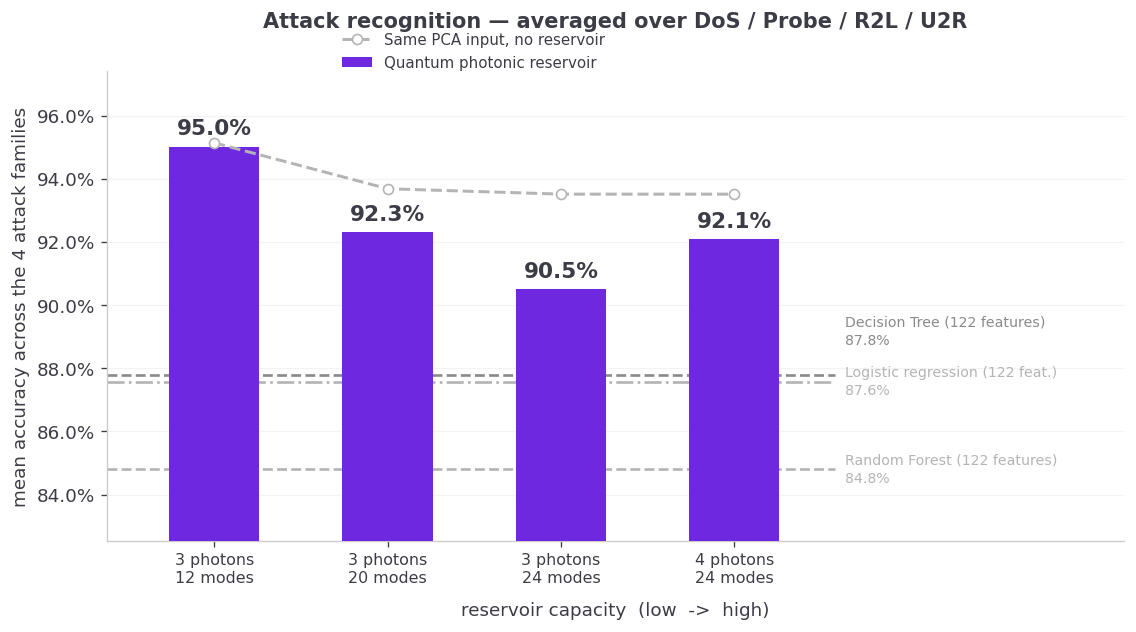

In [56]:
mean_atk_q = [float(np.mean([FAM[(c, "quantum")].loc[f, "recall"]
                             for f in FAM_ORDER])) for c in CONFIG_ORDER]
mean_atk_d = [float(np.mean([FAM[(c, "dials")].loc[f, "recall"]
                             for f in FAM_ORDER])) for c in CONFIG_ORDER]

fig, ax = plt.subplots(figsize=(9.6, 5.4))
ax.bar(x, mean_atk_q, BAR_W, color=PINK, zorder=3,
       label="Quantum photonic reservoir")
ax.plot(x, mean_atk_d, color=DIM, lw=1.8, ls="--", marker="o", ms=6,
        markerfacecolor="white", markeredgecolor=DIM, zorder=4,
        label="Same PCA input, no reservoir")

XEND = len(CONFIG_ORDER) - 0.42
refs3 = sorted([
    (BASE["supervised"]["Decision Tree"]["mean_attack_recall"],
     "Decision Tree (122 features)", DIM_DARK, "--"),
    (BASE["supervised"]["Random Forest"]["mean_attack_recall"],
     "Random Forest (122 features)", DIM, "--"),
    (BASE["supervised"]["Logistic Regression"]["mean_attack_recall"],
     "Logistic regression (122 feat.)", DIM, "-."),
], key=lambda r: r[0])

# Decision Tree (87.8%) and logistic regression (87.6%) nearly coincide, so
# their two-line captions would overlap. Push each label up until it clears
# the one below; the LINE still marks the true value.
MIN_LABEL_GAP = 0.016
placed = []
for val, lab, col, ls in refs3:
    ax.plot([-0.62, XEND], [val, val], color=col, lw=1.6, ls=ls, zorder=2)
    ytxt = val
    for prev in placed:
        if abs(ytxt - prev) < MIN_LABEL_GAP:
            ytxt = prev + MIN_LABEL_GAP
    placed.append(ytxt)
    ax.text(XEND + 0.06, ytxt, f"{lab}\n{val*100:.1f}%",
            fontsize=8.5, color=col, va="center", ha="left", linespacing=1.35)

for xi, v in zip(x, mean_atk_q):
    ax.annotate(f"{v*100:.1f}%", (xi, v), textcoords="offset points",
                xytext=(0, 7), ha="center", fontsize=13,
                fontweight="bold", color=INK, zorder=5)

allv = mean_atk_q + mean_atk_d + [
    BASE["supervised"][k]["mean_attack_recall"]
    for k in ("Decision Tree", "Random Forest", "Logistic Regression")]
lo, hi = min(allv), max(allv)
pad = (hi - lo) * 0.22
ax.set_ylim(lo - pad, hi + pad)

ax.set_xticks(x)
ax.set_xticklabels([CONFIG_LABEL[c] for c in CONFIG_ORDER], fontsize=9.5)
ax.set_ylabel("mean accuracy across the 4 attack families")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(-0.62, len(CONFIG_ORDER) + 1.25)
ax.set_xlabel("reservoir capacity  (low  ->  high)", labelpad=10)
ax.set_title("Attack recognition — averaged over DoS / Probe / R2L / U2R",
             pad=26, fontsize=12.5)
ax.grid(axis="y", alpha=0.55); ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(0.36, 1.11), fontsize=9)
plt.tight_layout(); save(fig, "13_attack_recognition"); plt.show()

### 13.2 The two accuracy tables, printed for the slide

In [57]:
print("=" * 78)
print("TABLE 1 - NOVELTY (zero-day): accuracy, trained on normal traffic only")
print("=" * 78)
t1 = pd.DataFrame({
    "readout dim": [READOUT_DIM[c] for c in CONFIG_ORDER],
    "QUANTUM": [f"{v*100:.2f}%" for v in nov_acc_q],
    "same PCA input": [f"{v*100:.2f}%" for v in nov_acc_dials],
    "classical 122-feat": [f"{v*100:.2f}%" for v in nov_acc_raw],
    "Isolation Forest": [f"{v*100:.2f}%" for v in nov_acc_if],
}, index=CONFIG_ORDER)
print(t1.to_string())
print(f"\n  trivial 'all attack' guess = {BASE_RATE*100:.2f}%   "
      f"(the floor any detector must beat)")
print("  accuracy = best achievable over all thresholds (upper bound)")

print("\n" + "=" * 78)
print("TABLE 2 - SUPERVISED: accuracy on known attack families")
print("=" * 78)
t2 = pd.DataFrame({
    "readout dim": [READOUT_DIM[c] for c in CONFIG_ORDER],
    "QUANTUM acc": [f"{v*100:.2f}%" for v in acc_q],
    "same PCA input": [f"{v*100:.2f}%" for v in acc_d],
    "QUANTUM attack-rec": [f"{v*100:.2f}%" for v in mean_atk_q],
}, index=CONFIG_ORDER)
print(t2.to_string())
print("\n  classical models on the full 122 features:")
for k, v in sorted(BASE["supervised"].items(), key=lambda kv: -kv[1]["accuracy"]):
    note = "  <- same 24-dim input as the reservoir" if "PCA-24" in k else ""
    print(f"    {k:30s} acc={v['accuracy']*100:6.2f}%  "
          f"attack-rec={v['mean_attack_recall']*100:6.2f}%{note}")

summary_tables = (
    "TABLE 1 - NOVELTY\n" + t1.to_string()
    + f"\n\ntrivial all-attack guess = {BASE_RATE*100:.2f}%\n\n"
    + "TABLE 2 - SUPERVISED\n" + t2.to_string() + "\n\nclassical (122 feat):\n"
    + "\n".join(f"  {k:30s} acc={v['accuracy']*100:6.2f}%  "
                f"attack-rec={v['mean_attack_recall']*100:6.2f}%"
                for k, v in sorted(BASE["supervised"].items(),
                                   key=lambda kv: -kv[1]["accuracy"])))
(FIGDIR / "accuracy_tables.txt").write_text(summary_tables, encoding="utf-8")
t1.to_csv(FIGDIR / "table1_novelty_accuracy.csv")
t2.to_csv(FIGDIR / "table2_supervised_accuracy.csv")
print(f"\nsaved -> {FIGDIR/'accuracy_tables.txt'} (+ 2 CSVs)")

TABLE 1 - NOVELTY (zero-day): accuracy, trained on normal traffic only
       readout dim QUANTUM same PCA input classical 122-feat Isolation Forest
3p12m          220  93.31%         92.84%             95.00%           93.55%
3p20m         1140  94.43%         94.72%             95.00%           93.55%
3p24m         2024  94.51%         94.93%             95.00%           93.55%
4p24m        10626  94.58%         94.93%             95.00%           93.55%

  trivial 'all attack' guess = 74.37%   (the floor any detector must beat)
  accuracy = best achievable over all thresholds (upper bound)

TABLE 2 - SUPERVISED: accuracy on known attack families
       readout dim QUANTUM acc same PCA input QUANTUM attack-rec
3p12m          220      95.55%         71.96%             95.02%
3p20m         1140      97.40%         76.69%             92.31%
3p24m         2024      97.66%         79.66%             90.50%
4p24m        10626      97.88%         79.66%             92.10%

  classical model

### What these two slides support — and what they do not

**Can say:**

* Zero-day: the reservoir is **competitive with Isolation Forest and a
  122-feature classical detector** while reading a 24-dim optical bottleneck,
  and it improves with capacity.
* Supervised: ~98% accuracy from 24 dimensions, **+18 points over the same
  input without the reservoir** — the reservoir is doing real work on its input.

**Cannot say:**

* "Quantum beats classical." On the supervised task **Random Forest wins**
  (99.9% vs 97.9%), and it still wins restricted to the same 24-dim PCA input
  (99.7%). The honest claim is efficiency and competitiveness, not superiority.
* Nothing here is established across seeds — single seed (42) throughout.
* Novelty accuracy is an **upper bound**: the threshold is picked with
  hindsight. At a fixed 1% false-alarm budget the quantum detector drops to
  ~43%, because the last percentile of normal traffic overlaps the attack
  scores. Quote the operating point whenever you quote the number.